# Pretrained FIM + ftnode structure outside the training data — diagnostics

**Question.** A pretrained ODE foundation model (FIM-ODE, [arXiv:2602.08733](https://arxiv.org/abs/2602.08733))
infers a vector field from a short window of observed data. The ftnode structure
$F(x,u)=A(x)\,(x-g(x,u))$, with $A$ negative definite *by construction*, keeps every
trajectory bounded. An earlier study (`FIM_analysis.ipynb`) tested the combination **inside**
the training data, where a cold model already fits, so a pretrained prior had little to add.

This notebook tests it **outside** the training data, on the Duffing oscillator. It asks:

1. Does the pretrained FIM prior carry to states the training data never visits?
2. How much of FIM should be retrained ("retuned") to keep that prior?
3. Does the bounded structure help or hurt there?

**Answer in one paragraph.** The pretrained FIM backbone gives **no measurable
out-of-distribution benefit** over a model trained from scratch, on any of the three tests.
The bounded structure **never diverges**, while free fields diverge on up to every test
trajectory. But where it has no data, the structure settles at the **edge of its bounded
equilibrium map** ($q=-R_g$), wherever that edge is. Combined with FIM and a short-rollout
objective, it also turns the true saddle into a **spurious sink**. Far from the data, the
structured fields that do form the saddle are under-damped and keep oscillating between the wells. The training objective matters more than how much of FIM is retrained.

Everything below reads saved results from `runs/fim_ood/` (produced by
`scripts/fim_ood_sweep.py` and `scripts/fim_ood_pilot.py`). No cell retrains a model. Run the
notebook from the repository root.

## The plant and what a model sees

State $x=(q,\dot q)\in\mathbb R^2$. The Duffing oscillator with a constant input $u$ per trajectory:

$$\ddot q+\delta\dot q+q^3-q=u,\qquad \delta=0.2,\quad u\sim\mathcal U[-0.25,0.25],$$

written as the first-order field $f^\ast(x,u)=\big(\dot q,\;-\delta\dot q-q^3+q+u\big)$. For
$u=0$ it has two stable wells at $q=\pm1$ and a saddle at $q=0$. The input shifts them slightly:
over $|u|\le0.25$ the wells lie in $0.84\le|q|\le1.11$ and the saddle in $|q|\le0.27$.

**Only $q$ is measured.** $\dot q$ is never observed. Each trajectory is cut into

- a **window** — the first $\tau=8$ samples of $q$ (0.4 s, step $h=0.05$), which every model sees, and
- a **target** — the next 600 samples (30 s), which a model must predict.

Every model starts its prediction from the same finite-difference estimate of the state at
the end of the window, $\dot q_0=(q_{-1}-q_{-2})/h$, $q_0=q_{-1}+h\dot q_0$, and integrates its
field $F$ with RK4. The prediction $\hat q_k$ is the first component of the integrated state.

The window is not test leakage. It is the measured past at prediction time, and every model gets
the same one. The models differ in how they use it: a model trained from scratch uses it only
for the start state; a FIM model also feeds it to FIM as **context**, from which FIM infers the
system's field.

In [1]:
import json, pathlib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams["font.family"] = "serif"
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "font.size": 10, "axes.axisbelow": True})

ROOT = pathlib.Path.cwd()
RUNS = ROOT / "runs/fim_ood"
SPLITS = ["trapped_lobe", "crossing_half", "far_field"]
SPLIT_TITLE = {"trapped_lobe": "Test 1 — trapped lobe",
               "crossing_half": "Test 2 — crossing half",
               "far_field": "Test 3 — far field"}

# Plain-language names for the parts of a cell name such as "S-R2-roll".
ARM = {"C1": "cold · MLP", "C2": "cold · $A(x-g)$",
       "Z": "FIM alone (no training)", "M": "FIM + MLP", "S": "FIM + $A(x-g)$"}
SCOPE = {"R0": "head finetune", "R1": "head + FIM decoder", "R2": "head + FIM finetune"}
OBJ = {"roll": "traj", "drift": "drift", "distill": "distillation"}

def parts(cell):
    p = cell.split("-")
    if len(p) == 3:
        return p[0], p[1], p[2]
    return p[0], None, (p[1] if len(p) == 2 else None)

def label(cell):
    a, s, o = parts(cell)
    return " · ".join([ARM[a]] + ([SCOPE[s]] if s else []) + ([OBJ[o]] if o else []))

CELLS = ["C1-roll", "C1-drift", "C2-roll", "C2-drift", "Z",
         "M-R0-roll", "M-R0-drift", "M-R1-roll", "M-R1-drift", "M-R2-roll", "M-R2-drift",
         "S-R0-roll", "S-R0-drift", "S-R1-roll", "S-R1-drift", "S-R2-roll", "S-R2-drift",
         "S-R0-distill"]

# Okabe-Ito colours: free vs structured, cold vs FIM.
C_FREE, C_STRUCT, C_FIM, C_TRUTH = "#E69F00", "#0072B2", "#009E73", "k"

## The three tests (data splits)

Each test trains on one region of the state space and tests on another. All trajectories use
the same plant, the same input distribution and the same window; only where they start differs.

**Test 1 — trapped lobe.** Train only on trajectories that can never leave the **right** well;
test only on trajectories that can never leave the **left** well. The model never sees the left
well or the saddle. "Can never leave" is exact, from the energy

$$E(x;u)=\tfrac12\dot q^2+\tfrac14q^4-\tfrac12q^2-uq,\qquad \dot E=-\delta\dot q^2\le0 .$$

The energy never increases, and on the line $q=q_s(u)$ (the saddle) $E\ge E_s(u)=E(q_s,0;u)$. So
a start with $E(x_0;u)<E_s(u)$ and $q_0>q_s(u)$ stays right of the saddle forever. The left test
set is the exact mirror image of a right set: the plant is unchanged by
$(q,\dot q,u)\mapsto(-q,-\dot q,-u)$.

**Test 2 — crossing half.** Train on starts with $q_0>0$ and no energy limit, so about 35% of the
training trajectories cross into the left well. Test on starts with $q_0<0$. The left well is
reachable through the crossers, so this test is close to in-distribution.

**Test 3 — far field.** Train in the standard box $[-1.6,1.6]\times[-1,1]$; test on starts with
$|q_0|\in[2,4]$. Far from the origin the true field grows like $-q^3$, while the bounded structure
grows at most linearly — a known limit of the structure.

Sizes: 64 training trajectories of 200 steps (data seed 0); 32 validation trajectories from the
training region (data seed 1); 320 test trajectories of 600 steps (data seeds 1000–1004).

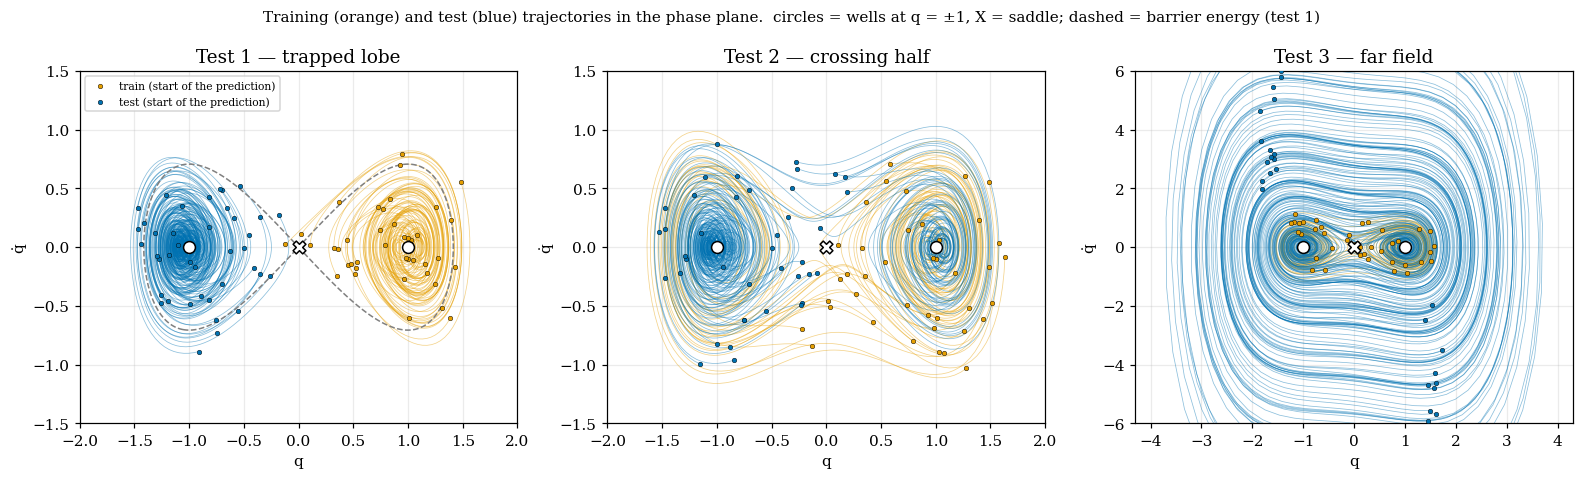

In [2]:
from ftnode.ood_splits import SplitConfig, make_split, saddle
from ftnode.systems import DuffingDataConfig, make_dataset

def train_set(split, n=40):
    if split == "far_field":
        return make_dataset(DuffingDataConfig(n_traj=n, L=200, seed=0))
    return make_split(SplitConfig({"trapped_lobe": "trapped_right", "crossing_half": "half_right"}[split],
                                  n_traj=n, L=200, seed=0))

def test_set(split, n=40):
    region = {"trapped_lobe": "trapped_left", "crossing_half": "half_left", "far_field": "far_ring"}[split]
    return make_split(SplitConfig(region, n_traj=n, L=600, seed=1000))

fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.4))
qq, vv = np.meshgrid(np.linspace(-2.2, 2.2, 300), np.linspace(-1.6, 1.6, 300))
for ax, split in zip(axes, SPLITS):
    tr, te = train_set(split), test_set(split)
    for ds, col, lab in [(tr, C_FREE, "train"), (te, C_STRUCT, "test")]:
        for i in range(len(ds)):
            ax.plot(ds.Xfull[i, :, 0], ds.Xfull[i, :, 1], color=col, lw=0.5, alpha=0.45)
        ax.scatter(ds.Xfull[:, 0, 0], ds.Xfull[:, 0, 1], s=9, color=col, edgecolor="k", lw=0.3,
                   zorder=3, label=f"{lab} (start of the prediction)")
    if split == "trapped_lobe":   # the barrier energy contour at u = 0
        ax.contour(qq, vv, 0.5 * vv**2 + 0.25 * qq**4 - 0.5 * qq**2, levels=[0.0],
                   colors="grey", linewidths=1, linestyles="--")
    ax.scatter([-1, 1], [0, 0], marker="o", s=60, color="w", edgecolor="k", zorder=4)
    ax.scatter([0], [0], marker="X", s=70, color="w", edgecolor="k", zorder=4)
    ax.set_title(SPLIT_TITLE[split]); ax.set_xlabel("q"); ax.set_ylabel("q̇")
    lim = 4.3 if split == "far_field" else 2.0
    ax.set_xlim(-lim, lim); ax.set_ylim(-(6 if split == "far_field" else 1.5), 6 if split == "far_field" else 1.5)
axes[0].legend(fontsize=7, loc="upper left")
fig.suptitle("Training (orange) and test (blue) trajectories in the phase plane.  "
             "circles = wells at q = ±1, X = saddle; dashed = barrier energy (test 1)", fontsize=10)
plt.tight_layout(); plt.show()

## The models

Five kinds of model ("arms"), all predicting with the same start-state estimate and RK4:

| Arm | Field $F(x,u)$ | Uses the window as FIM context? |
|---|---|---|
| **scratch · free MLP** | an MLP on $[x,u]$, trained from random init | no |
| **scratch · structured** | $A(x)\,(x-g(x,u))$, trained from random init | no |
| **FIM alone** | the pretrained FIM drift $f_{\text{FIM}}(x)$, no training | yes |
| **FIM + free MLP head** | an MLP on $[f_{\text{FIM}}(x),x,u]$ | yes |
| **FIM + structured head** | $A$ and $g$ read $[f_{\text{FIM}}(x),x]$, and $g$ also reads $u$ | yes |

**The structured field.** $A(x)=-(\sigma_{\min}I+P(x))+K(x)$ with $P\succeq0$ symmetric and $K$
skew, so $\operatorname{sym}A\preceq-\sigma_{\min}I$ at every $x$. The equilibrium map is bounded,
$g=R_g\tanh(\cdot)$ with $R_g=2$, so every equilibrium of the field lies in the box $|g_i|\le2$.
Together these keep every trajectory in a bounded ball — by construction, for any parameters.

**FIM.** A 13M-parameter neural operator. Its **encoder** (1.58M parameters) reads the context
window; a query embedding (0.07M) and a **decoder** of 8 cross-attention layers with an output MLP
(6.45M) produce the drift at any query state. A separate uncertainty head (4.87M) is not on the
drift path and is never trained. FIM runs with its dropout switched off.

The two head models have matched sizes (about 26,600 trainable head parameters each), so a
difference between them is the structure, not the capacity.

## How FIM is retuned — scope and objective

Each FIM-head model is trained in one of three **scopes** — how much of FIM is allowed to change:

| Scope | What trains | FIM parameters that change |
|---|---|---|
| **head only** | the head; all of FIM frozen | 0 |
| **head + FIM decoder** | the head, the query embedding and the decoder; the context encoder frozen | 6.52M |
| **head + all of FIM** | the head and the whole FIM drift path | 8.10M |

FIM parameters train at a learning rate of $5\times10^{-6}$ (FIM's own finetuning rate); heads
and scratch models at $3\times10^{-3}$.

and with one of three **objectives** — what the loss compares. All use the measured $q$ only:

- **Short rollout.** Pick a random start time in each training trajectory, estimate the state from
  the 8 samples before it, integrate 6 RK4 steps, and compare the predicted $q$ with the measured $q$:
  $\ \mathcal L=\tfrac17\sum_{k=0}^{6}(\hat q_k-q_k)^2$.
- **Drift matching.** Estimate the state and its derivative from the measured $q$ by finite
  differences, $\hat x_k=(q_k,\hat{\dot q}_k)$ and $\widehat{\dot x}_k=(\hat{\dot q}_k,\hat{\ddot q}_k)$, with
  $\hat{\dot q}_k=(q_{k+1}-q_{k-1})/2h$ and $\hat{\ddot q}_k=(q_{k+1}-2q_k+q_{k-1})/h^2$, and fit the
  field directly: $\ \mathcal L=\lVert F(\hat x_k,u)-\widehat{\dot x}_k\rVert^2$. No integration. This is
  the estimated-label version of FIM's own pretraining objective.
- **Distillation** (structured head, head only). Fit $A(x)(x-g)\approx f_{\text{FIM}}(x)$ to the
  frozen FIM drift at the reconstructed states.

The scratch models use the short-rollout and drift-matching objectives. That gives 18 models per
test: 4 scratch, FIM alone, 6 FIM + free MLP head, 7 FIM + structured head.

**Hypotheses.** *Forgetting:* retraining more of FIM on one region overwrites what FIM knows about
other regions, so "head only" keeps the prior best. *Context:* on test 1 the FIM models beat the
scratch models, because only they read the left-well window as context.

## Training budget and model selection — the pilot

A fixed number of training steps is not fair to every objective. A pilot (one seed, trained long,
test 1 training region) showed why. It logged the drift error against the true field on the
in-distribution validation set every 100 steps, and how far FIM's weights and drift moved.

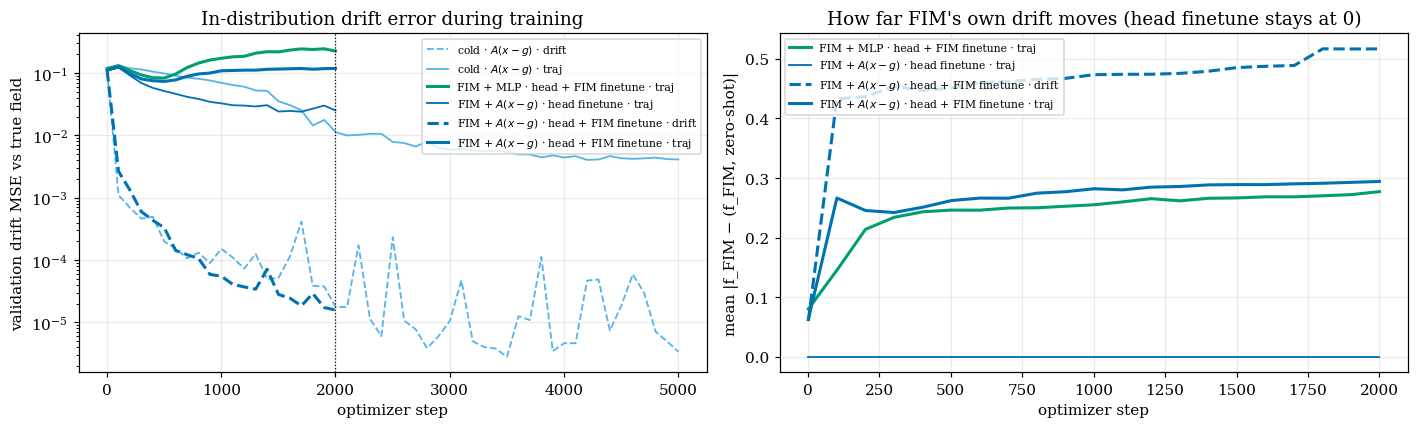

In [3]:
pilot = {p.stem: json.loads(p.read_text()) for p in sorted((RUNS / "pilot/trapped_lobe").glob("*.json"))}
fig, axes = plt.subplots(1, 2, figsize=(13.0, 4.0))
for cell, r in pilot.items():
    st = [row["step"] for row in r["log"]]
    a, s, o = parts(cell)
    col = {"C2": "#56B4E9", "M": C_FIM, "S": C_STRUCT}[a]   # same colours as the other figures
    ls = "-" if o == "roll" else "--"
    lw = 2.0 if s == "R2" else 1.2
    axes[0].semilogy(st, [row["val_drift_mse"] for row in r["log"]], ls, color=col, lw=lw, label=label(cell))
    if "backbone_drift_change" in r["log"][0]:
        axes[1].plot(st, [row["backbone_drift_change"] for row in r["log"]], ls, color=col, lw=lw, label=label(cell))
axes[0].axvline(2000, color="k", lw=0.8, ls=":")
axes[0].set_xlabel("optimizer step"); axes[0].set_ylabel("validation drift MSE vs true field")
axes[0].set_title("In-distribution drift error during training"); axes[0].legend(fontsize=7)
axes[1].set_xlabel("optimizer step"); axes[1].set_ylabel("mean |f_FIM − (f_FIM, zero-shot)|")
axes[1].set_title("How far FIM's own drift moves (head finetune stays at 0)"); axes[1].legend(fontsize=7)
plt.tight_layout(); plt.show()

**Reading.** (1) FIM does move at $5\times10^{-6}$: its drift shifts by 0.27–0.52 on average after
2,000 steps, so the three scopes are genuinely different models. (2) Drift-matching models (dashed)
improve steadily. (3) Short-rollout models that retrain FIM (solid, thick) are best near step 500 and
then **get worse** while their training loss keeps falling: a 6-step $q$ rollout does not pin the
field, and a free FIM uses that freedom. (4) The scratch short-rollout model is still improving at
5,000 steps.

So every model trains **up to a cap** (2,000 steps with FIM, 5,000 from scratch), is validated every
25 steps (100 from scratch) on the in-distribution validation set — with the drift-matching loss from
the measured $q$, not the true field — and the **best validated state is restored** before the test.
The untrained start is a candidate. Selection never sees the test region.

## How the predictions are scored

All three tests end in a well: Duffing is damped, so every true trajectory is inside a well by step
400 (in test 3 about a third still oscillate inside their well). The useful question is **where each prediction settles**. For each of the 320
test trajectories, compare the mean of $\hat q$ over the last 200 steps with the same mean of the
true $q$, and sort the prediction into one bin:

| Bin | Rule |
|---|---|
| **true well** | within 0.3 of the true resting place |
| **other well** | within 0.3 of the mirror place (the other well) |
| **settled at q≈0** | at rest (std of $\hat q$ over the last 200 steps $\le0.2$) within 0.3 of $q=0$, where the true system has a saddle, not a resting place |
| **edge \|q\|≈2** | at rest within 0.3 of $\lvert q\rvert=2$, the edge of the structured model's equilibrium box |
| **still oscillating** | not at rest (std over the last 200 steps $>0.2$) and not in either well — typically swinging between the wells |
| **other bounded** | bounded, none of the above |
| **diverged** | a non-finite prediction, or $\lvert\hat q\rvert>5$ in the last 200 steps |

Two common scores mislead here. The mean squared error over all 600 steps is dominated by any
diverged trajectory, and on test 1 a model that simply sinks to $q=0$ gets the lowest mean. A count
of "wrong wells" by the **sign** of $q$ calls a prediction that settles at $q=-2$ correct for a true
well at $q=-1$.

In [4]:
TOL, DIV, OSC = 0.3, 5.0, 0.2
BINS = ["true well", "other well", "settled at q≈0", "edge |q|≈2", "still oscillating", "other bounded", "diverged"]
BIN_COLOR = ["#009E73", "#E69F00", "#CC79A7", "#56B4E9", "#F0E442", "#BBBBBB", "#D55E00"]
IDX = {b: k for k, b in enumerate(BINS)}

def classify(P, Y):
    Pn = np.where(np.isfinite(P), P, np.nan)
    with np.errstate(all="ignore"):
        div = ~np.isfinite(P).all(1) | (np.nanmax(np.abs(Pn[:, 400:]), 1) > DIV)
        lp = np.nanmean(Pn[:, 400:], 1)
        ls = np.nanstd(Pn[:, 400:], 1)
    ly = Y[:, 400:].mean(1)
    rest = ls <= OSC
    b = np.full(len(P), IDX["other bounded"])
    b[~rest] = IDX["still oscillating"]
    b[rest & (np.abs(np.abs(lp) - 2) < TOL)] = IDX["edge |q|≈2"]
    b[rest & (np.abs(lp) < TOL)] = IDX["settled at q≈0"]
    b[np.abs(lp + ly) < TOL] = IDX["other well"]
    b[np.abs(lp - ly) < TOL] = IDX["true well"]
    b[div] = IDX["diverged"]
    return b, lp

def load(split):
    # Per cell and model seed: the bin counts, the late means, a few example predictions and the record.
    out, Y = {}, None
    for cell in CELLS:
        recs = []
        for j in sorted((RUNS / split / cell).glob("seed*.json")):
            r = json.loads(j.read_text())
            z = np.load(j.with_suffix(".npz"))
            P, Yc = z["qhat"].astype(np.float64), z["y"].astype(np.float64)
            Y = Yc if Y is None else Y
            b, lp = classify(P, Yc)
            recs.append(dict(seed=r["seed"], counts=np.bincount(b, minlength=len(BINS)), late=lp, bins=b,
                             examples=P[:6].astype(np.float32), rec=r))
        out[cell] = recs
    return out, Y

RES, TRUTH = {}, {}
for split in SPLITS:
    RES[split], TRUTH[split] = load(split)

def mean_counts(split, cell):
    return np.mean([r["counts"] for r in RES[split][cell]], 0)

print("loaded:", {s: sum(len(v) for v in RES[s].values()) for s in SPLITS}, "jobs per test")

loaded: {'trapped_lobe': 86, 'crossing_half': 86, 'far_field': 86} jobs per test


In [5]:
def settle_figure(split, ax):
    y = np.arange(len(CELLS))[::-1]
    left = np.zeros(len(CELLS))
    for k, (name, col) in enumerate(zip(BINS, BIN_COLOR)):
        v = np.array([mean_counts(split, c)[k] for c in CELLS])
        ax.barh(y, v, left=left, color=col, edgecolor="k", lw=0.3, label=name)
        left += v
    for yi, c in zip(y, CELLS):
        ax.text(322, yi, f"{mean_counts(split, c)[0]:.0f}", va="center", fontsize=7)
    ax.set_yticks(y); ax.set_yticklabels([label(c) for c in CELLS], fontsize=7.5)
    ax.set_xlim(0, 345); ax.set_xlabel("test trajectories (of 320), mean over 5 model seeds")
    ax.set_title(SPLIT_TITLE[split] + " — where the predictions settle  (number = true well)")
    for yy in [len(CELLS) - 4.5, len(CELLS) - 5.5, len(CELLS) - 11.5]:
        ax.axhline(yy, color="k", lw=0.6)
    # Group labels on the right, one per block between the black lines.
    n = len(CELLS)
    groups = [("Cold models", n - 4, n - 1), ("FIM (zero shot)", n - 5, n - 5),
              ("FIM + MLP", n - 11, n - 6), ("FIM + $A(x-g)$", 0, n - 12)]
    tr = ax.get_yaxis_transform()   # x in axes units, y in data units
    for name, lo, hi in groups:
        ax.plot([1.075, 1.075], [lo - 0.4, hi + 0.4], color="k", lw=1.2, transform=tr, clip_on=False)
        ax.text(1.09, (lo + hi) / 2, name, transform=tr, va="center", ha="left", fontsize=9)

## Test 1 — trapped lobe: train on the right well, test on the left well

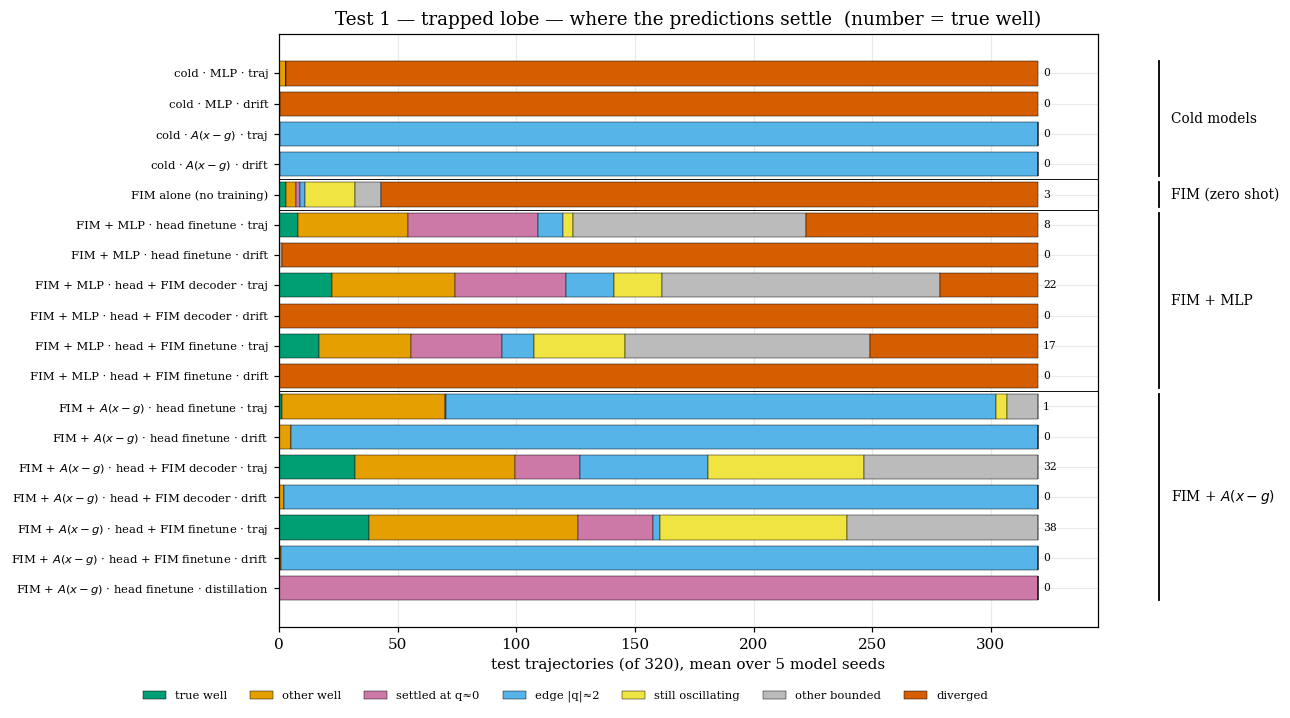

In [6]:
fig, ax = plt.subplots(figsize=(12.0, 6.6))
settle_figure("trapped_lobe", ax)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.35, -0.09), ncol=7, frameon=False)
plt.tight_layout(); plt.show()

**Reading.**

1. **No model learns the unseen well.** The best models — FIM + structured head with FIM decoder or
   all of FIM retrained, short rollout — send 10–12% of the trajectories to the left well. Every
   scratch model sends none.
2. **The structured models never diverge, but settle at the edge of their equilibrium box.** The
   scratch structured models and every drift-matched structured head rest at $q\approx-2=-R_g$, where
   $g=R_g\tanh(\cdot)$ saturates. With no data in a region, the structure's equilibrium is where the
   bounded map saturates, not where the dynamics put it.
3. **Free fields diverge** — scratch free MLP and every drift-matched FIM + MLP head diverge on almost
   all 320 trajectories; FIM alone diverges on 277.
4. **Forgetting is not supported.** With the short rollout, retraining more of FIM sends *more*
   trajectories to the true well than head-only (about 30 against 1 for the structured head), and
   also more to the trained right well. A free FIM widens the spread rather than erasing a prior.
5. **Distillation is degenerate.** Fitting the head to the zero-shot FIM drift made the validation
   loss worse from the first step on every seed, so the untrained head was restored. Its field is a
   sink at the origin, hence "settled at q≈0" for all 320.

## Test 2 — crossing half: train on $q_0>0$, test on $q_0<0$

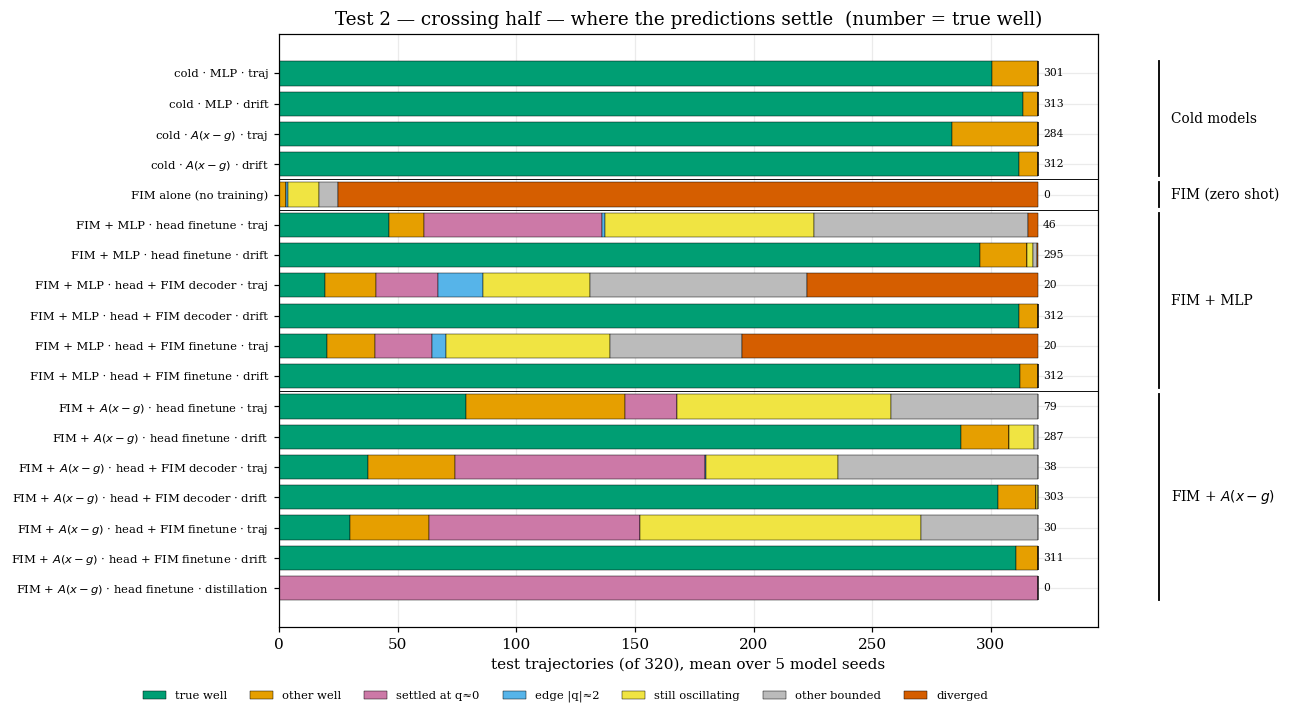

In [7]:
fig, ax = plt.subplots(figsize=(12.0, 6.6))
settle_figure("crossing_half", ax)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.35, -0.09), ncol=7, frameon=False)
plt.tight_layout(); plt.show()

**Reading.** The training data reaches the left well through the crossers, so this test is close to
in-distribution — and it shows. Every **drift-matched** model, scratch or FIM, free or structured,
settles 287–313 of 320 in the true well. The scratch free MLP is the best (313). The **short-rollout
FIM models fail**: the structured heads leave up to 105 trajectories at rest at $q\approx0$ — where the
true system has a saddle — and up to 119 still oscillating; the free heads diverge on up to 125.
The diagnostics below show that this resting place is a stable equilibrium of the learned field.

## Test 3 — far field: train in the standard box, test from $|q_0|\in[2,4]$

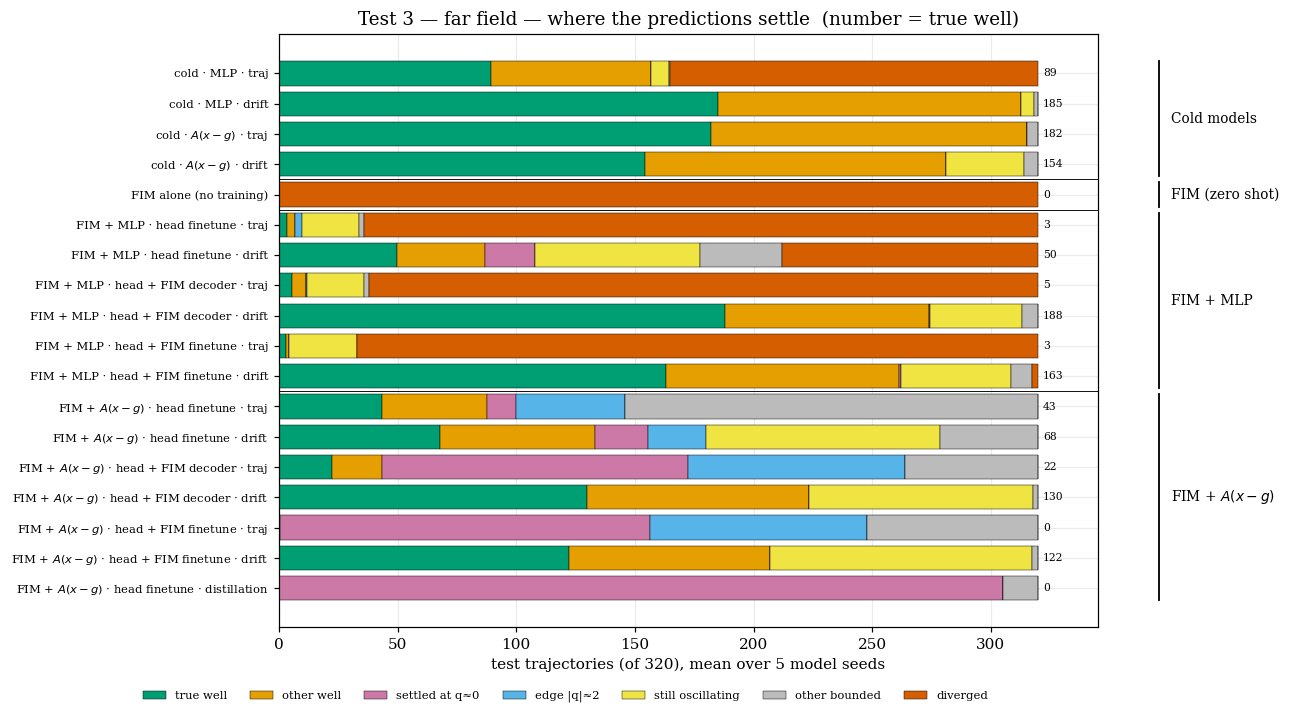

In [8]:
fig, ax = plt.subplots(figsize=(12.0, 6.6))
settle_figure("far_field", ax)
ax.legend(fontsize=7.5, loc="upper center", bbox_to_anchor=(0.35, -0.09), ncol=7, frameon=False)
plt.tight_layout(); plt.show()

**Reading.** From a high-energy start the true system settles about half in each well, and the well
it picks is sensitive to the start. The best models (FIM + MLP head with the decoder retrained, the
scratch free MLP, the scratch structured model with the short rollout) settle 86–98% of the
trajectories in *a* well but pick the true one only 57–59% of the time. The short-rollout structured
FIM heads leave up to 156 trajectories at rest at $q\approx0$ and up to about 90 at the edge
$|q|\approx2$. The drift-trained structured heads instead leave 94–110 still oscillating between the
wells: they form the saddle correctly but are under-damped at high energy (see the diagnostics below). The short-rollout FIM + MLP heads diverge on 287–320.

The structured models briefly overshoot to $|\hat q|\approx8$ on 24–60 trajectories, and every one comes
back — the bound the structure guarantees is a ball much larger than the data, not the data box.

## Example predictions

Three test trajectories per test (model seed 0). Black dashed: the truth. A prediction that leaves
the plotted range diverged.

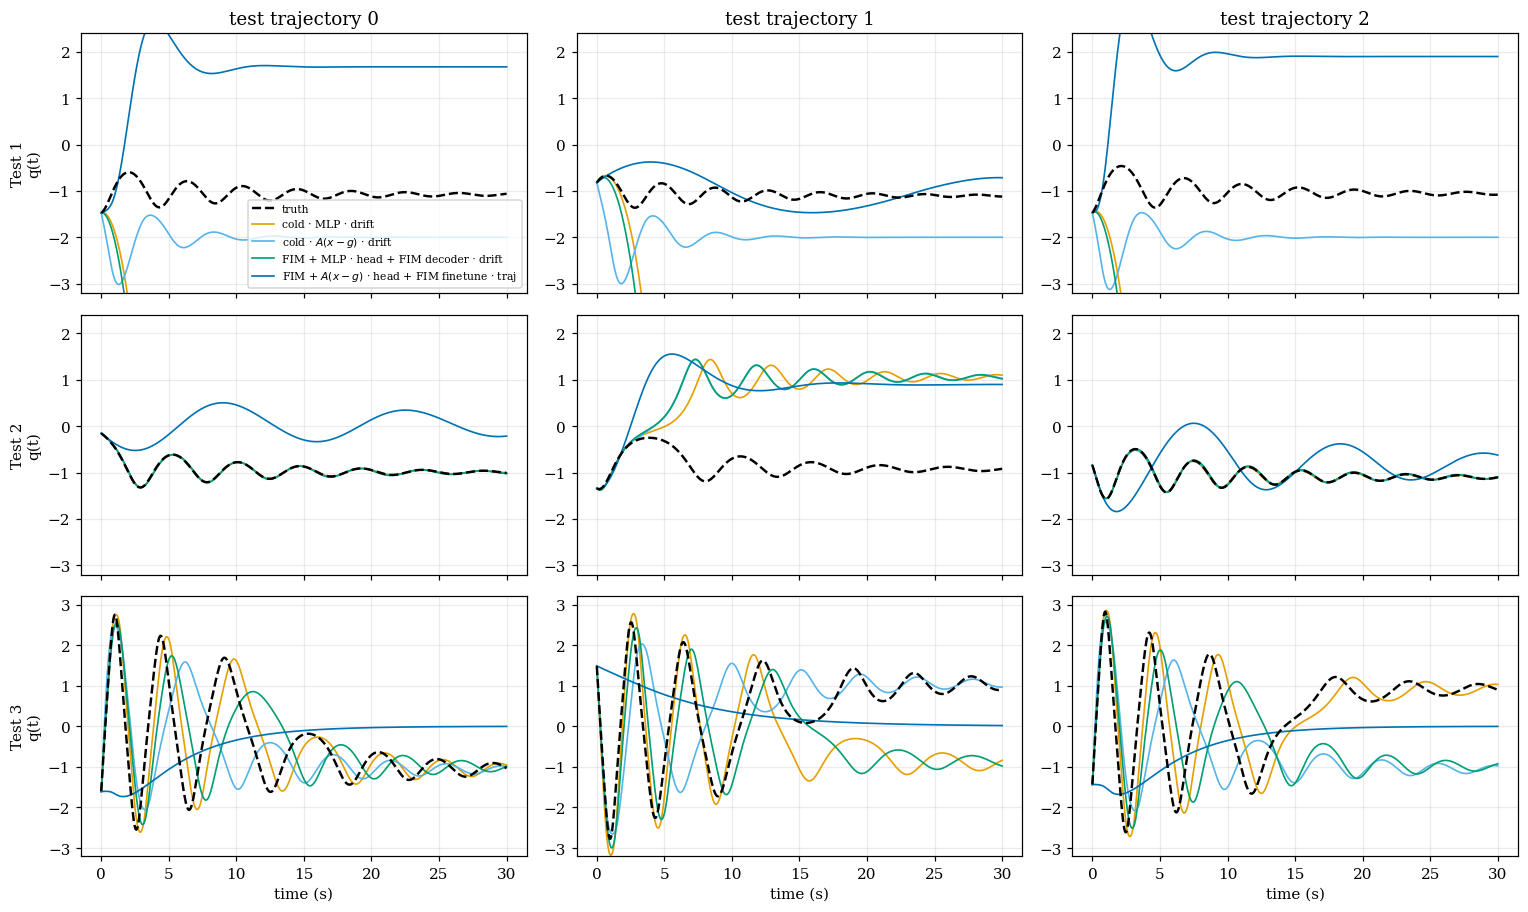

In [9]:
SHOW = [("C1-drift", C_FREE), ("C2-drift", "#56B4E9"), ("M-R1-drift", C_FIM), ("S-R2-roll", C_STRUCT)]
t = np.arange(601) * 0.05
fig, axes = plt.subplots(3, 3, figsize=(14.0, 8.4), sharex=True)
for row, split in enumerate(SPLITS):
    for col in range(3):
        ax = axes[row, col]
        ax.plot(t, TRUTH[split][col], "--", color=C_TRUTH, lw=1.6, label="truth", zorder=5)
        for cell, c in SHOW:
            ax.plot(t, RES[split][cell][0]["examples"][col], color=c, lw=1.1, label=label(cell))
        ax.set_ylim(-3.2, 3.2 if split == "far_field" else 2.4)
        if col == 0:
            ax.set_ylabel(SPLIT_TITLE[split].split(" — ")[0] + "\nq(t)")
        if row == 0:
            ax.set_title(f"test trajectory {col}")
for ax in axes[-1]:
    ax.set_xlabel("time (s)")
axes[0, 0].legend(fontsize=7, loc="lower right")
plt.tight_layout(); plt.show()

## Fitting the training region against extrapolating

Drift error against the true field, on the training trajectories (horizontal) and on the test
trajectories (vertical), one point per model (mean over seeds). Filled = drift matching, open = short
rollout; colour = arm.

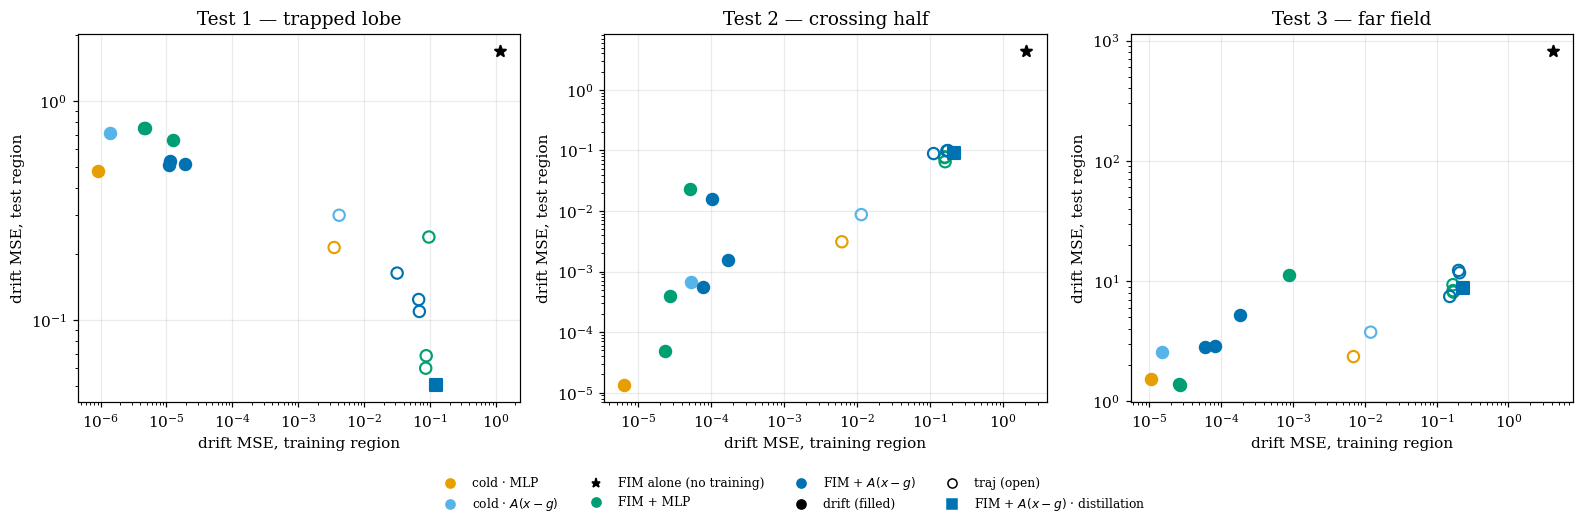

In [10]:
ARM_COL = {"C1": C_FREE, "C2": "#56B4E9", "Z": "k", "M": C_FIM, "S": C_STRUCT}
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.3))
for ax, split in zip(axes, SPLITS):
    for cell in CELLS:
        a, s, o = parts(cell)
        tr = np.mean([r["rec"]["drift_mse_train"] for r in RES[split][cell]])
        te = np.mean([r["rec"]["drift_mse_test"] for r in RES[split][cell]])
        filled = o == "drift"
        ax.scatter(tr, te, s=55, marker={"roll": "o", "drift": "o", "distill": "s", None: "*"}[o],
                   facecolor=ARM_COL[a] if (filled or o is None or o == "distill") else "none",
                   edgecolor=ARM_COL[a], lw=1.4, zorder=3)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel("drift MSE, training region"); ax.set_ylabel("drift MSE, test region")
    ax.set_title(SPLIT_TITLE[split])
handles = [plt.Line2D([], [], marker="*" if a == "Z" else "o", ls="", color=c, label=ARM[a])
           for a, c in ARM_COL.items()]
handles += [plt.Line2D([], [], marker="o", ls="", mfc="k", mec="k", label="drift (filled)"),
            plt.Line2D([], [], marker="o", ls="", mfc="none", mec="k", label="traj (open)"),
            plt.Line2D([], [], marker="s", ls="", color=C_STRUCT, label="FIM + $A(x-g)$ · distillation")]
fig.legend(handles=handles, fontsize=8, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()

**Reading.** Drift matching fits the training region about 100 to 100,000 times better than the short
rollout (left part of each panel). On test 1 that tight fit does **not** carry to the unseen well: the
drift-matched models have the largest test error. On test 2, where the training data reaches the test
region, the drift-matched models are also best on the test; on test 3 they are mostly best. The star is
FIM alone, without training.

## Where the structured models end up

Where do the structured models (scratch structured and FIM + structured head) come to rest? Below,
the late mean of $\hat q$ pooled over all structured models and seeds, against the truth.

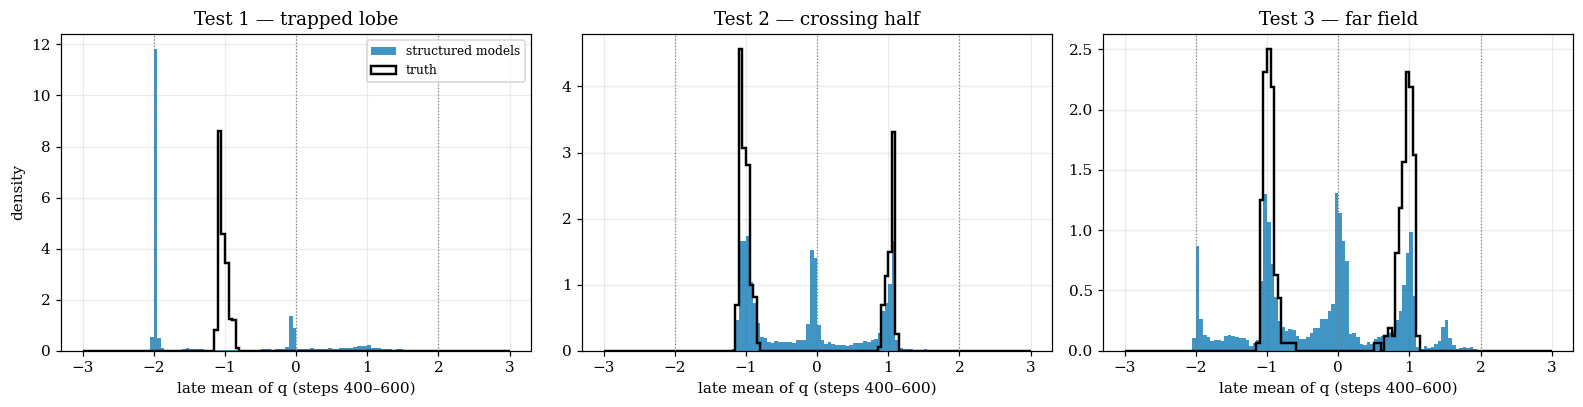

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14.5, 3.8), sharey=False)
edges = np.linspace(-3, 3, 121)
for ax, split in zip(axes, SPLITS):
    late = np.concatenate([r["late"][r["bins"] != IDX["diverged"]] for c in CELLS if parts(c)[0] in ("C2", "S")
                           for r in RES[split][c]])
    truth = TRUTH[split][:, 400:].mean(1)
    ax.hist(late, bins=edges, density=True, color=C_STRUCT, alpha=0.75, label="structured models")
    ax.hist(truth, bins=edges, density=True, histtype="step", color="k", lw=1.6, label="truth")
    for v, txt in [(-2, "edge"), (0, "saddle"), (2, "edge")]:
        ax.axvline(v, color="grey", lw=0.8, ls=":")
    ax.set_title(SPLIT_TITLE[split]); ax.set_xlabel("late mean of q (steps 400–600)")
axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** Three patterns appear where the truth has none:

- **$q=\pm2$, the edge of the equilibrium box** (test 1, and some short-rollout heads in test 3). Where
  the model has no data, $g$ saturates at $\pm R_g$ and the field's resting place goes with it.
- **At rest near $q=0$, the saddle** (tests 2 and 3, short-rollout FIM heads only). The learned field has a
  stable equilibrium where the true system has a saddle.
- **A broad spread between the wells** (test 3, drift-trained heads). These predictions have not come to
  rest: they keep swinging between the wells.

The next section tests the first two directly.

## Diagnostics — the equilibrium-box edge and the saddle

Two follow-up runs test the mechanisms behind the patterns above. Both reuse the sweep code
(`scripts/fim_ood_sweep.py`), with results under `runs/fim_ood_diag/`.

**1. Does the resting place follow the box edge?** The cold $A(x-g)$ models are retrained on test 1 with
the equilibrium-map bound $R_g=2,3,4$ (5 seeds each, both objectives). If the resting place in the unseen
well is set by the saturation of $g$, it should move to $q=-R_g$. The true well stays at $q\approx-1$, which
lies inside the box for every $R_g$, so a larger box cannot help on its own.

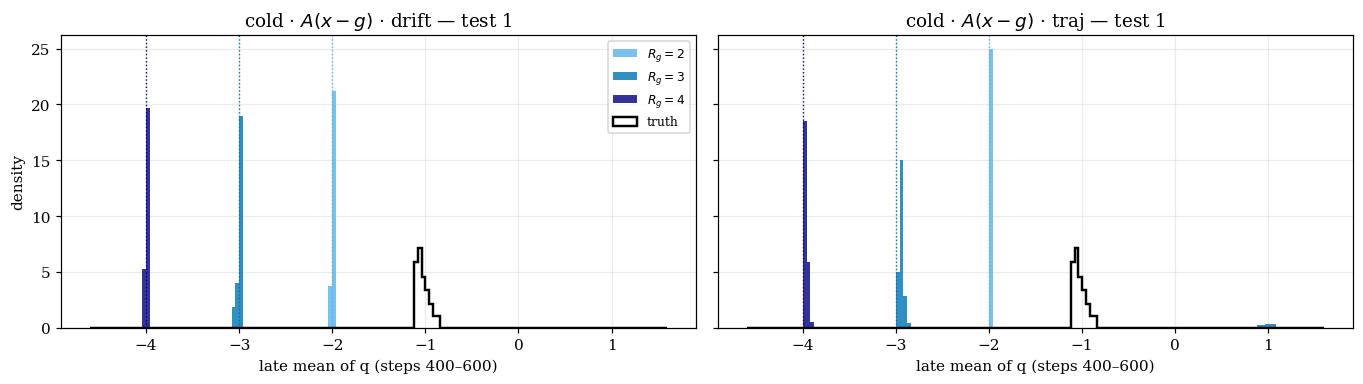

In [12]:
DIAG = ROOT / "runs/fim_ood_diag"
fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.6), sharey=True)
edges = np.linspace(-4.6, 1.6, 156)
rg_col = {2: "#56B4E9", 3: "#0072B2", 4: "#000080"}
truth1 = TRUTH["trapped_lobe"][:, 400:].mean(1)
for ax, cell in zip(axes, ["C2-drift", "C2-roll"]):
    for g, col in rg_col.items():
        P = np.concatenate([np.load(f)["qhat"] for f in sorted((DIAG / f"Rg{g}/trapped_lobe/{cell}").glob("seed*.npz"))])
        late = P[:, 400:].astype(float).mean(1)
        ax.hist(late, bins=edges, density=True, color=col, alpha=0.8, label=f"$R_g={g}$")
        ax.axvline(-g, color=col, lw=0.9, ls=":")
    ax.hist(truth1, bins=edges, density=True, histtype="step", color="k", lw=1.6, label="truth")
    ax.set_title(f"{label(cell)} — test 1"); ax.set_xlabel("late mean of q (steps 400–600)")
axes[0].set_ylabel("density"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Reading.** The resting place follows $-R_g$ exactly: $-2.00$, $-3.00$ and $-3.99$ (median) with drift
matching, and $-1.98$, $-2.95$, $-3.98$ with the short rollout. No trajectory reaches the true well at any
$R_g$. In a region without data, the structure's equilibrium sits where $g$ saturates, and a larger box
moves the error outward.

**2. Is the resting place near $q=0$ a stable equilibrium?** Selected models are retrained with their
fitted fields saved (2 seeds each): the short-rollout FIM + $A(x-g)$ heads on test 2, which settle near
$q=0$; the drift-trained one as a control; and the drift-trained and cold $A(x-g)$ models on test 3. A FIM
field depends on its context, so the analysis (`scripts/fim_ood_equilibria.py`) works per test trajectory.
It binds that trajectory's window, runs Newton's method from the true saddle $(q_s(u),0)$ to find the
model's nearest equilibrium, and classifies it by the eigenvalues of $D_xF$: a **sink** if no eigenvalue
has a positive real part, a **saddle** if one does, a **source** if both do. The true saddle has one
eigenvalue at $+0.905$ (for $u=0$). On the true field the method recovers that saddle.

equilibrium found (/320)  \
test          model                                        seed                             
crossing half FIM + $A(x-g)$ · head finetune · traj        0                           74   
                                                           1                          117   
              FIM + $A(x-g)$ · head + FIM decoder · traj   0                          320   
                                                           1                           79   
              FIM + $A(x-g)$ · head + FIM finetune · drift 0                          320   
                                                           1                          320   
              FIM + $A(x-g)$ · head + FIM finetune · traj  0                           87   
                                                           1                          320   
far field     cold · $A(x-g)$ · drift                      0                          320   
                                                           1                          320   
              cold · $A(x-g)$ · traj                       0                          320   
                                                           1                          320   
              FIM + $A(x-g)$ · head finetune · drift       0                           17   
                                                           1                           27   
              FIM + $A(x-g)$ · head + FIM decoder · drift  0                          249   
                                                           1                          242   
              FIM + $A(x-g)$ · head + FIM finetune · drift 0                          260   
                                                           1                          244   

                                                                 sink  saddle  \
test          model                                        seed                 
crossing half FIM + $A(x-g)$ · head finetune · traj        0       31      39   
                                                           1       27       0   
              FIM + $A(x-g)$ · head + FIM decoder · traj   0      320       0   
                                                           1       79       0   
              FIM + $A(x-g)$ · head + FIM finetune · drift 0        0     320   
                                                           1        0     320   
              FIM + $A(x-g)$ · head + FIM finetune · traj  0       81       0   
                                                           1      320       0   
far field     cold · $A(x-g)$ · drift                      0        0     320   
                                                           1        0     320   
              cold · $A(x-g)$ · traj                       0        0     320   
                                                           1        0     320   
              FIM + $A(x-g)$ · head finetune · drift       0        0      17   
                                                           1        1      26   
              FIM + $A(x-g)$ · head + FIM decoder · drift  0        0     249   
                                                           1        0     242   
              FIM + $A(x-g)$ · head + FIM finetune · drift 0        0     260   
                                                           1        6     238   

                                                                 source  \
test          model                                        seed           
crossing half FIM + $A(x-g)$ · head finetune · traj        0          4   
                                                           1         90   
              FIM + $A(x-g)$ · head + FIM decoder · traj   0          0   
                                                           1          0   
              FIM + $A(x-g)$ · head + FIM finetune · drift 0          0   
                                                          

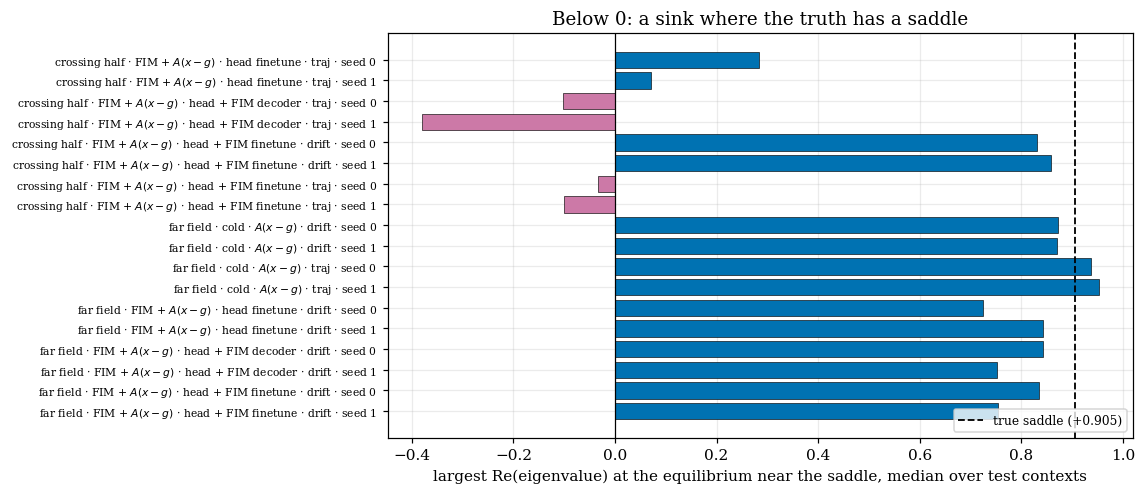

In [13]:
rows = []
for split in ["crossing_half", "far_field"]:
    for o in json.loads((DIAG / "sink" / split / "equilibria_summary.json").read_text()):
        cls = o["near_saddle_class"]
        pct = o["near_saddle_max_re_pct"]
        rows.append({"test": SPLIT_TITLE[split].split(" — ")[1], "model": label(o["cell"]), "seed": o["seed"],
                     "equilibrium found (/320)": o["near_saddle_found"],
                     "sink": cls["sink"], "saddle": cls["saddle"], "source": cls["source"],
                     "largest Re(λ), median": None if pct is None else round(pct[1], 3)})
EQ = pd.DataFrame(rows)
display(EQ.set_index(["test", "model", "seed"]))

fig, ax = plt.subplots(figsize=(10.5, 4.6))
lab = [f"{r['test']} · {r['model']} · seed {r['seed']}" for _, r in EQ.iterrows()]
y = np.arange(len(EQ))[::-1]
v = EQ["largest Re(λ), median"].astype(float).values
ax.barh(y, v, color=[C_STRUCT if x > 0 else "#CC79A7" for x in v], edgecolor="k", lw=0.4)
ax.axvline(0.905, color="k", ls="--", lw=1.2, label="true saddle (+0.905)")
ax.axvline(0, color="k", lw=0.8)
ax.set_yticks(y); ax.set_yticklabels(lab, fontsize=7)
ax.set_xlabel("largest Re(eigenvalue) at the equilibrium near the saddle, median over test contexts")
ax.legend(fontsize=8, loc="lower right"); ax.set_title("Below 0: a sink where the truth has a saddle")
plt.tight_layout(); plt.show()

**Reading.**

- **The spurious sink is real, but only for FIM + $A(x-g)$ trained with the short rollout.** Of the six
  such runs on test 2, two have a **sink** at the saddle position in all 320 contexts (largest real part
  $\approx-0.10$), and their predictions come to rest there. In the other four, an equilibrium near the
  saddle exists in only 74–117 contexts. Those are mostly sinks; in one run they are mostly weak sources
  ($\approx+0.07$), which the trajectories keep orbiting instead of resting. Only one run (head
  finetune, seed 0) has some saddles (39).
- **With drift matching, the same structured head forms the saddle** in all 320 contexts, with an
  unstable eigenvalue of $0.83$–$0.86$ against the true $0.905$. The **cold** $A(x-g)$ models form it with
  either objective. So the structure can represent the saddle; the sink comes from combining the FIM
  feature with the short-rollout objective.
- **Test 3's drift-trained structured heads have a proper saddle** (median largest real part
  $0.72$–$0.84$). Their predictions near $q\approx0$ are still oscillating: the fields do not dissipate
  enough energy far from the data. That is under-damping, not a wrong attractor.

## Across the three tests

,best FIM model (true well /320),best scratch model (true well /320),"max diverged, structured","max diverged, free"
test,,,,
Test 1 — trapped lobe,38 (FIM + $A(x-g)$ · head + FIM finetune · traj),0 (cold · $A(x-g)$ · traj),0,320
Test 2 — crossing half,312 (FIM + MLP · head + FIM finetune · drift),313 (cold · MLP · drift),0,295
Test 3 — far field,188 (FIM + MLP · head + FIM decoder · drift),185 (cold · MLP · drift),0,320


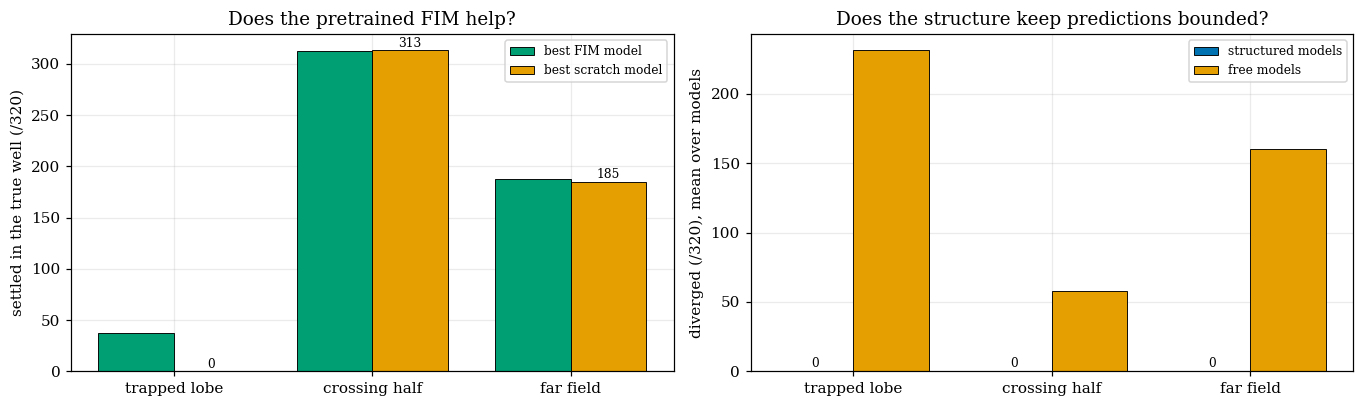

In [14]:
FIM_ARMS, SCRATCH = ("Z", "M", "S"), ("C1", "C2")
rows = []
for split in SPLITS:
    best = lambda arms: max(((mean_counts(split, c)[0], c) for c in CELLS if parts(c)[0] in arms))
    bf, bs = best(FIM_ARMS), best(SCRATCH)
    div_struct = max(mean_counts(split, c)[IDX["diverged"]] for c in CELLS if parts(c)[0] in ("C2", "S"))
    div_free = max(mean_counts(split, c)[IDX["diverged"]] for c in CELLS if parts(c)[0] in ("C1", "M", "Z"))
    rows.append({"test": SPLIT_TITLE[split], "best FIM model (true well /320)": f"{bf[0]:.0f}  ({label(bf[1])})",
                 "best scratch model (true well /320)": f"{bs[0]:.0f}  ({label(bs[1])})",
                 "max diverged, structured": f"{div_struct:.0f}", "max diverged, free": f"{div_free:.0f}"})
pd.set_option("display.max_colwidth", 80)
display(pd.DataFrame(rows).set_index("test"))

fig, axes = plt.subplots(1, 2, figsize=(12.5, 3.8))
x = np.arange(3); w = 0.38
bf = [max(mean_counts(s, c)[0] for c in CELLS if parts(c)[0] in FIM_ARMS) for s in SPLITS]
bs = [max(mean_counts(s, c)[0] for c in CELLS if parts(c)[0] in SCRATCH) for s in SPLITS]
axes[0].bar(x - w/2, bf, w, color=C_FIM, edgecolor="k", lw=0.6, label="best FIM model")
axes[0].bar(x + w/2, bs, w, color=C_FREE, edgecolor="k", lw=0.6, label="best scratch model")
axes[0].set_xticks(x); axes[0].set_xticklabels([SPLIT_TITLE[s].split(" — ")[1] for s in SPLITS])
axes[0].set_ylabel("settled in the true well (/320)"); axes[0].legend(fontsize=8)
axes[0].set_title("Does the pretrained FIM help?")
ds = [np.mean([mean_counts(s, c)[IDX["diverged"]] for c in CELLS if parts(c)[0] in ("C2", "S")]) for s in SPLITS]
df = [np.mean([mean_counts(s, c)[IDX["diverged"]] for c in CELLS if parts(c)[0] in ("C1", "M", "Z")]) for s in SPLITS]
axes[1].bar(x - w/2, ds, w, color=C_STRUCT, edgecolor="k", lw=0.6, label="structured models")
axes[1].bar(x + w/2, df, w, color=C_FREE, edgecolor="k", lw=0.6, label="free models")
axes[1].set_xticks(x); axes[1].set_xticklabels([SPLIT_TITLE[s].split(" — ")[1] for s in SPLITS])
axes[1].set_ylabel("diverged (/320), mean over models"); axes[1].legend(fontsize=8)
axes[1].set_title("Does the structure keep predictions bounded?")
for i, v in enumerate(ds):
    axes[1].text(i - w/2, v + 3, f"{v:.0f}", ha="center", fontsize=8)
for i, v in enumerate(bs):
    axes[0].text(i + w/2, v + 3, f"{v:.0f}", ha="center", fontsize=8)
plt.tight_layout(); plt.show()

In [15]:
# Full table: mean ± std over the 5 model seeds, per test and bin.
tab = {}
for split in SPLITS:
    for c in CELLS:
        C = np.array([r["counts"] for r in RES[split][c]])
        for k, b in enumerate(BINS):
            tab.setdefault((label(c),), {})[(SPLIT_TITLE[split].split(" — ")[1], b)] = \
                f"{C[:, k].mean():.0f}" + (f" ± {C[:, k].std():.0f}" if len(C) > 1 else "")
table = pd.DataFrame(tab).T
table.index = [i[0] for i in table.index]
display(table)

trapped lobe             \
                                                 true well other well   
cold · MLP · traj                                    0 ± 0      3 ± 3   
cold · MLP · drift                                   0 ± 0      1 ± 0   
cold · $A(x-g)$ · traj                               0 ± 0      1 ± 1   
cold · $A(x-g)$ · drift                              0 ± 0      1 ± 0   
FIM alone (no training)                                  3          4   
FIM + MLP · head finetune · traj                    8 ± 12    47 ± 14   
FIM + MLP · head finetune · drift                    0 ± 0      0 ± 0   
FIM + MLP · head + FIM decoder · traj               22 ± 7    52 ± 29   
FIM + MLP · head + FIM decoder · drift               0 ± 0      0 ± 0   
FIM + MLP · head + FIM finetune · traj              17 ± 9    39 ± 28   
FIM + MLP · head + FIM finetune · drift              0 ± 0      0 ± 0   
FIM + $A(x-g)$ · head finetune · traj                1 ± 2    69 ± 73   
FIM + $A(x-g)$ · head finetune · drift               0 ± 0      5 ± 2   
FIM + $A(x-g)$ · head + FIM decoder · traj         32 ± 27    68 ± 27   
FIM + $A(x-g)$ · head + FIM decoder · drift          0 ± 0      2 ± 1   
FIM + $A(x-g)$ · head + FIM finetune · traj        38 ± 21    88 ± 31   
FIM + $A(x-g)$ · head + FIM finetune · drift         0 ± 0      1 ± 1   
FIM + $A(x-g)$ · head finetune · distillation        0 ± 0      0 ± 0   

                                                                         \
                                              settled at q≈0 edge |q|≈2   
cold · MLP · traj                                      0 ± 0      0 ± 0   
cold · MLP · drift                                     0 ± 0      0 ± 0   
cold · $A(x-g)$ · traj                                 0 ± 0    319 ± 1   
cold · $A(x-g)$ · drift                                0 ± 0    319 ± 0   
FIM alone (no training)                                    2          2   
FIM + MLP · head finetune · traj                     54 ± 44     11 ± 6   
FIM + MLP · head finetune · drift                      0 ± 0      0 ± 0   
FIM + MLP · head + FIM decoder · traj                47 ± 25     20 ± 8   
FIM + MLP · head + FIM decoder · drift                 0 ± 0      0 ± 0   
FIM + MLP · head + FIM finetune · traj               39 ± 25     13 ± 8   
FIM + MLP · head + FIM finetune · drift                0 ± 0      0 ± 0   
FIM + $A(x-g)$ · head finetune · traj                  1 ± 1   232 ± 80   
FIM + $A(x-g)$ · head finetune · drift                 0 ± 0    315 ± 2   
FIM + $A(x-g)$ · head + FIM decoder · traj           27 ± 19    54 ± 92   
FIM + $A(x-g)$ · head + FIM decoder · drift            0 ± 0    318 ± 1   
FIM + $A(x-g)$ · head + FIM finetune · traj          32 ± 19      3 ± 3   
FIM + $A(x-g)$ · head + FIM finetune · drift           0 ± 0    319 ± 1   
FIM + $A(x-g)$ · head finetune · distillation        320 ± 0      0 ± 0   

                                                                               \
                                              still oscillating other bounded   
cold · MLP · traj                                         0 ± 0         0 ± 0   
cold · MLP · drift                                        0 ± 0         0 ± 0   
cold · $A(x-g)$ · traj                                    0 ± 0         0 ± 0   
cold · $A(x-g)$ · drift                                   0 ± 0         0 ± 0   
FIM alone (no training)                                      21            11   
FIM + MLP · head finetune · traj                          4 ± 5       98 ± 45   
FIM + MLP · head finetune · drift                         0 ± 0         1 ± 2   
FIM + MLP · head + FIM decoder · traj                   20 ± 28      117 ± 34   
FIM + MLP · head + FIM decoder · drift                    0 ± 0         0 ± 0   
FIM + MLP · head + FIM finetune · traj                  38 ± 42      103 ± 58   
FIM + MLP · head + FIM finetune · drift                   0 ± 0         0 ± 0   
FIM + $A(x-g)$ · head finetune 

## Run time

All runs are on CPU: 12 parallel workers × 4 threads on a 48-core machine, one test ≈ 4.5 h
(86 runs). The cell below reads each run's training and test time.

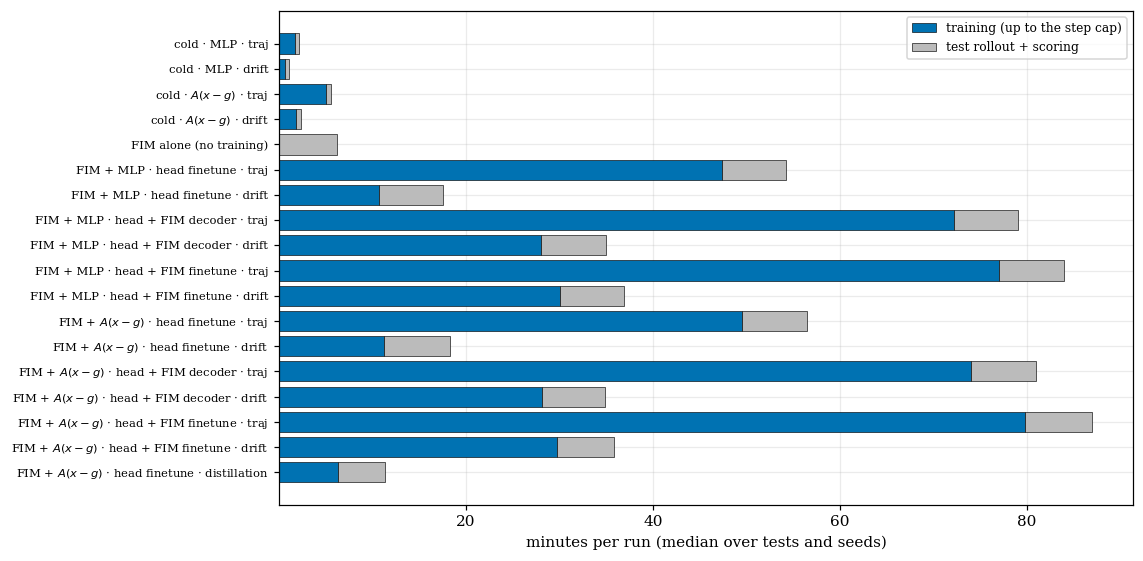

In [16]:
fig, ax = plt.subplots(figsize=(10.5, 5.2))
y = np.arange(len(CELLS))[::-1]
tr = [np.median([r["rec"]["timings_s"]["train"] for s in SPLITS for r in RES[s][c]]) / 60 for c in CELLS]
ev = [np.median([r["rec"]["timings_s"]["eval"] for s in SPLITS for r in RES[s][c]]) / 60 for c in CELLS]
ax.barh(y, tr, color=C_STRUCT, edgecolor="k", lw=0.4, label="training (up to the step cap)")
ax.barh(y, ev, left=tr, color="#BBBBBB", edgecolor="k", lw=0.4, label="test rollout + scoring")
ax.set_yticks(y); ax.set_yticklabels([label(c) for c in CELLS], fontsize=7.5)
ax.set_xlabel("minutes per run (median over tests and seeds)"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Caveats

- **One training set per test** (data seed 0); the five seeds vary the model initialization only.
- **The training budget was set on test 1 only.** Tests 2 and 3 reuse it. Each run's validation curve is
  saved, so convergence can be checked afterwards.
- **The equilibrium diagnostics use 2 model seeds per model** and selected models only. They show the
  mechanism, not effect sizes.
- **The FIM models use FIM's output drift as a feature.** A structured foundation model would read FIM's
  internal context embedding and train across many systems. This study is a proxy for that design, on one
  system.
- **Far-field direction and return-to-box metrics were not computed**; test 3 is scored by where the
  predictions settle.

## Summary

- **The pretrained FIM backbone gives no measurable out-of-distribution benefit** over a model trained
  from scratch: 312 vs 313 (test 2), 188 vs 185 (test 3), 38 vs 0 (test 1, where both are poor).
- **The bounded structure never diverges**, on any test, for any objective. Free fields diverge on up to
  all 320 trajectories.
- **Outside its data, the structure comes to rest at the edge of its equilibrium box** ($q=-R_g$, for
  any $R_g$). A structured foundation model needs an equilibrium map whose extrapolation the context
  decides, not the saturation of $g$.
- **FIM + $A(x-g)$ with the short rollout turns the true saddle into a sink.** The same head with drift
  matching, and the cold structured models, form the saddle. Far from the data, the structured fields
  that form it are under-damped.
- **The objective matters more than how much of FIM is retrained.** Drift matching wins wherever the
  training data reaches the test region; a short rollout with FIM free to change often diverges.
- **Retraining more of FIM does not cause forgetting here** — no scope kept a usable prior of the unseen
  well to begin with.